# Prediksi Kelayakan Air Minum
---

## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar belakang**: Sebuah lembaga penyedia air bersih atau otoritas pengawasan kualitas air ingin membangun sistem prediktif untuk menentukan apakah sampel air layak dikonsumsi/ diminum (Potability = 1) atau tidak layak minum (Potability = 0) berdasarkan parameter fisik dan kimia air. Sistem ini membantu mempercepat skrining kualitas air, memprioritaskan pengujian laboratorium lanjutan pada sampel berisiko, serta mendukung pengambilan keputusan kesehatan masyarakat.
2. **Masalah**: Lembaga tersebut tidak memiliki sistem untuk memprediksi apakah air layak untuk dikonsumsi atau tidak serta skrining kelayakan air masih dilakukan secara bekala secara manual.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **LightGBM** untuk memprediksi secara otomatis apakah air tersebut layak untuk dikonsumsi.

---
## 2. Data Preparation

### 2.1 Import library

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [3]:
df = pd.read_csv('water_potability.csv', na_values=['NA', 'N/A', 'NaN', '', ' '])
df.columns = df.columns.str.strip()

### 2.3 Menampilkan data teratas dan data terbawah

In [4]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [5]:
df.tail()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1
3275,7.874671,195.102299,17404.177061,7.509306,NaN,327.459760,16.140368,78.698446,2.309149,1


### 2.4 Memeriksa informasi data

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [7]:
print(f'Jumlah data: {df.size}')

print(f'\nJumlah missing value: {df.isnull().sum().sum()}')
print(f'---missing value per kolom--- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'Jumlah data duplikat: {df.duplicated().sum()}')

Jumlah data: 32760

Jumlah missing value: 1434
---missing value per kolom--- 
ph                 491
Sulfate            781
Trihalomethanes    162
dtype: int64
Jumlah data duplikat: 0


---
## 3. Explaratory Data Analysis (EDA)

### 3.1 Memeriksa deskripsi data

In [8]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


### 3.2 Memeriksa outlier dengan IQR dan Z-Score

In [9]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outliers = []

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        median = df[col].median()
        mean = df[col].mean()
        std = df[col].std()
        skew = df[col].skew()
        min = df[col].min()
        max = df[col].max()
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'kemiringan': skew,
            'min': min,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max,
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z.shape[0],
        })

pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,kemiringan,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,ph,7.080795,1.594320,0.025630,0.000000,6.093092,7.036752,8.062066,14.000000,3.139631,11.015527,46,16
1,Hardness,196.369496,32.879761,-0.039342,47.432000,176.850538,196.967627,216.667456,323.124000,117.125160,276.392834,83,18
2,Solids,22014.092526,8768.570828,0.621634,320.942611,15666.690297,20927.833607,27332.762127,61227.196008,-1832.417449,44831.869873,47,20
3,Chloramines,7.122277,1.583085,-0.012098,0.352000,6.127421,7.130299,8.114887,13.127000,3.146221,11.096086,61,20
4,Sulfate,333.775777,41.416840,-0.035947,129.000000,307.699498,333.073546,359.950170,481.030642,229.323489,438.326179,41,17
5,Conductivity,426.205111,80.824064,0.264490,181.483754,365.734414,421.884968,481.792304,753.342620,191.647579,655.879140,11,7
6,Organic_carbon,14.284970,3.308162,0.025533,2.200000,12.065801,14.218338,16.557652,28.300000,5.328026,23.295427,25,4
7,Trihalomethanes,66.396293,16.175008,-0.083031,0.738000,55.844536,66.622485,77.337473,124.000000,23.605130,109.576879,33,12
8,Turbidity,3.966786,0.780382,-0.007817,1.450000,3.439711,3.955028,4.500320,6.739000,1.848797,6.091233,19,8
9,Potability,0.390110,0.487849,0.450784,0.000000,0.000000,0.000000,1.000000,1.000000,-1.500000,2.500000,0,0


### 3.3 Visualisasi outlier dengan Boxplot

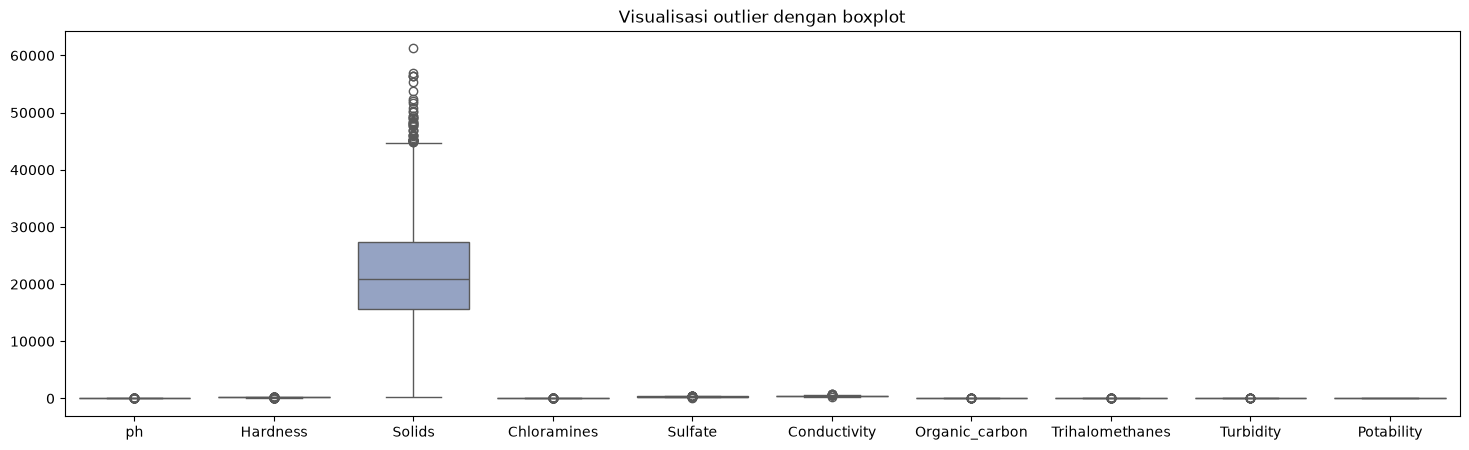

In [10]:
plt.figure(figsize=(18, 5))
sns.boxplot(data=df, palette='Set2')
plt.title('Visualisasi outlier dengan boxplot')
plt.show()

### 3.4 Visualisasi distribusi data

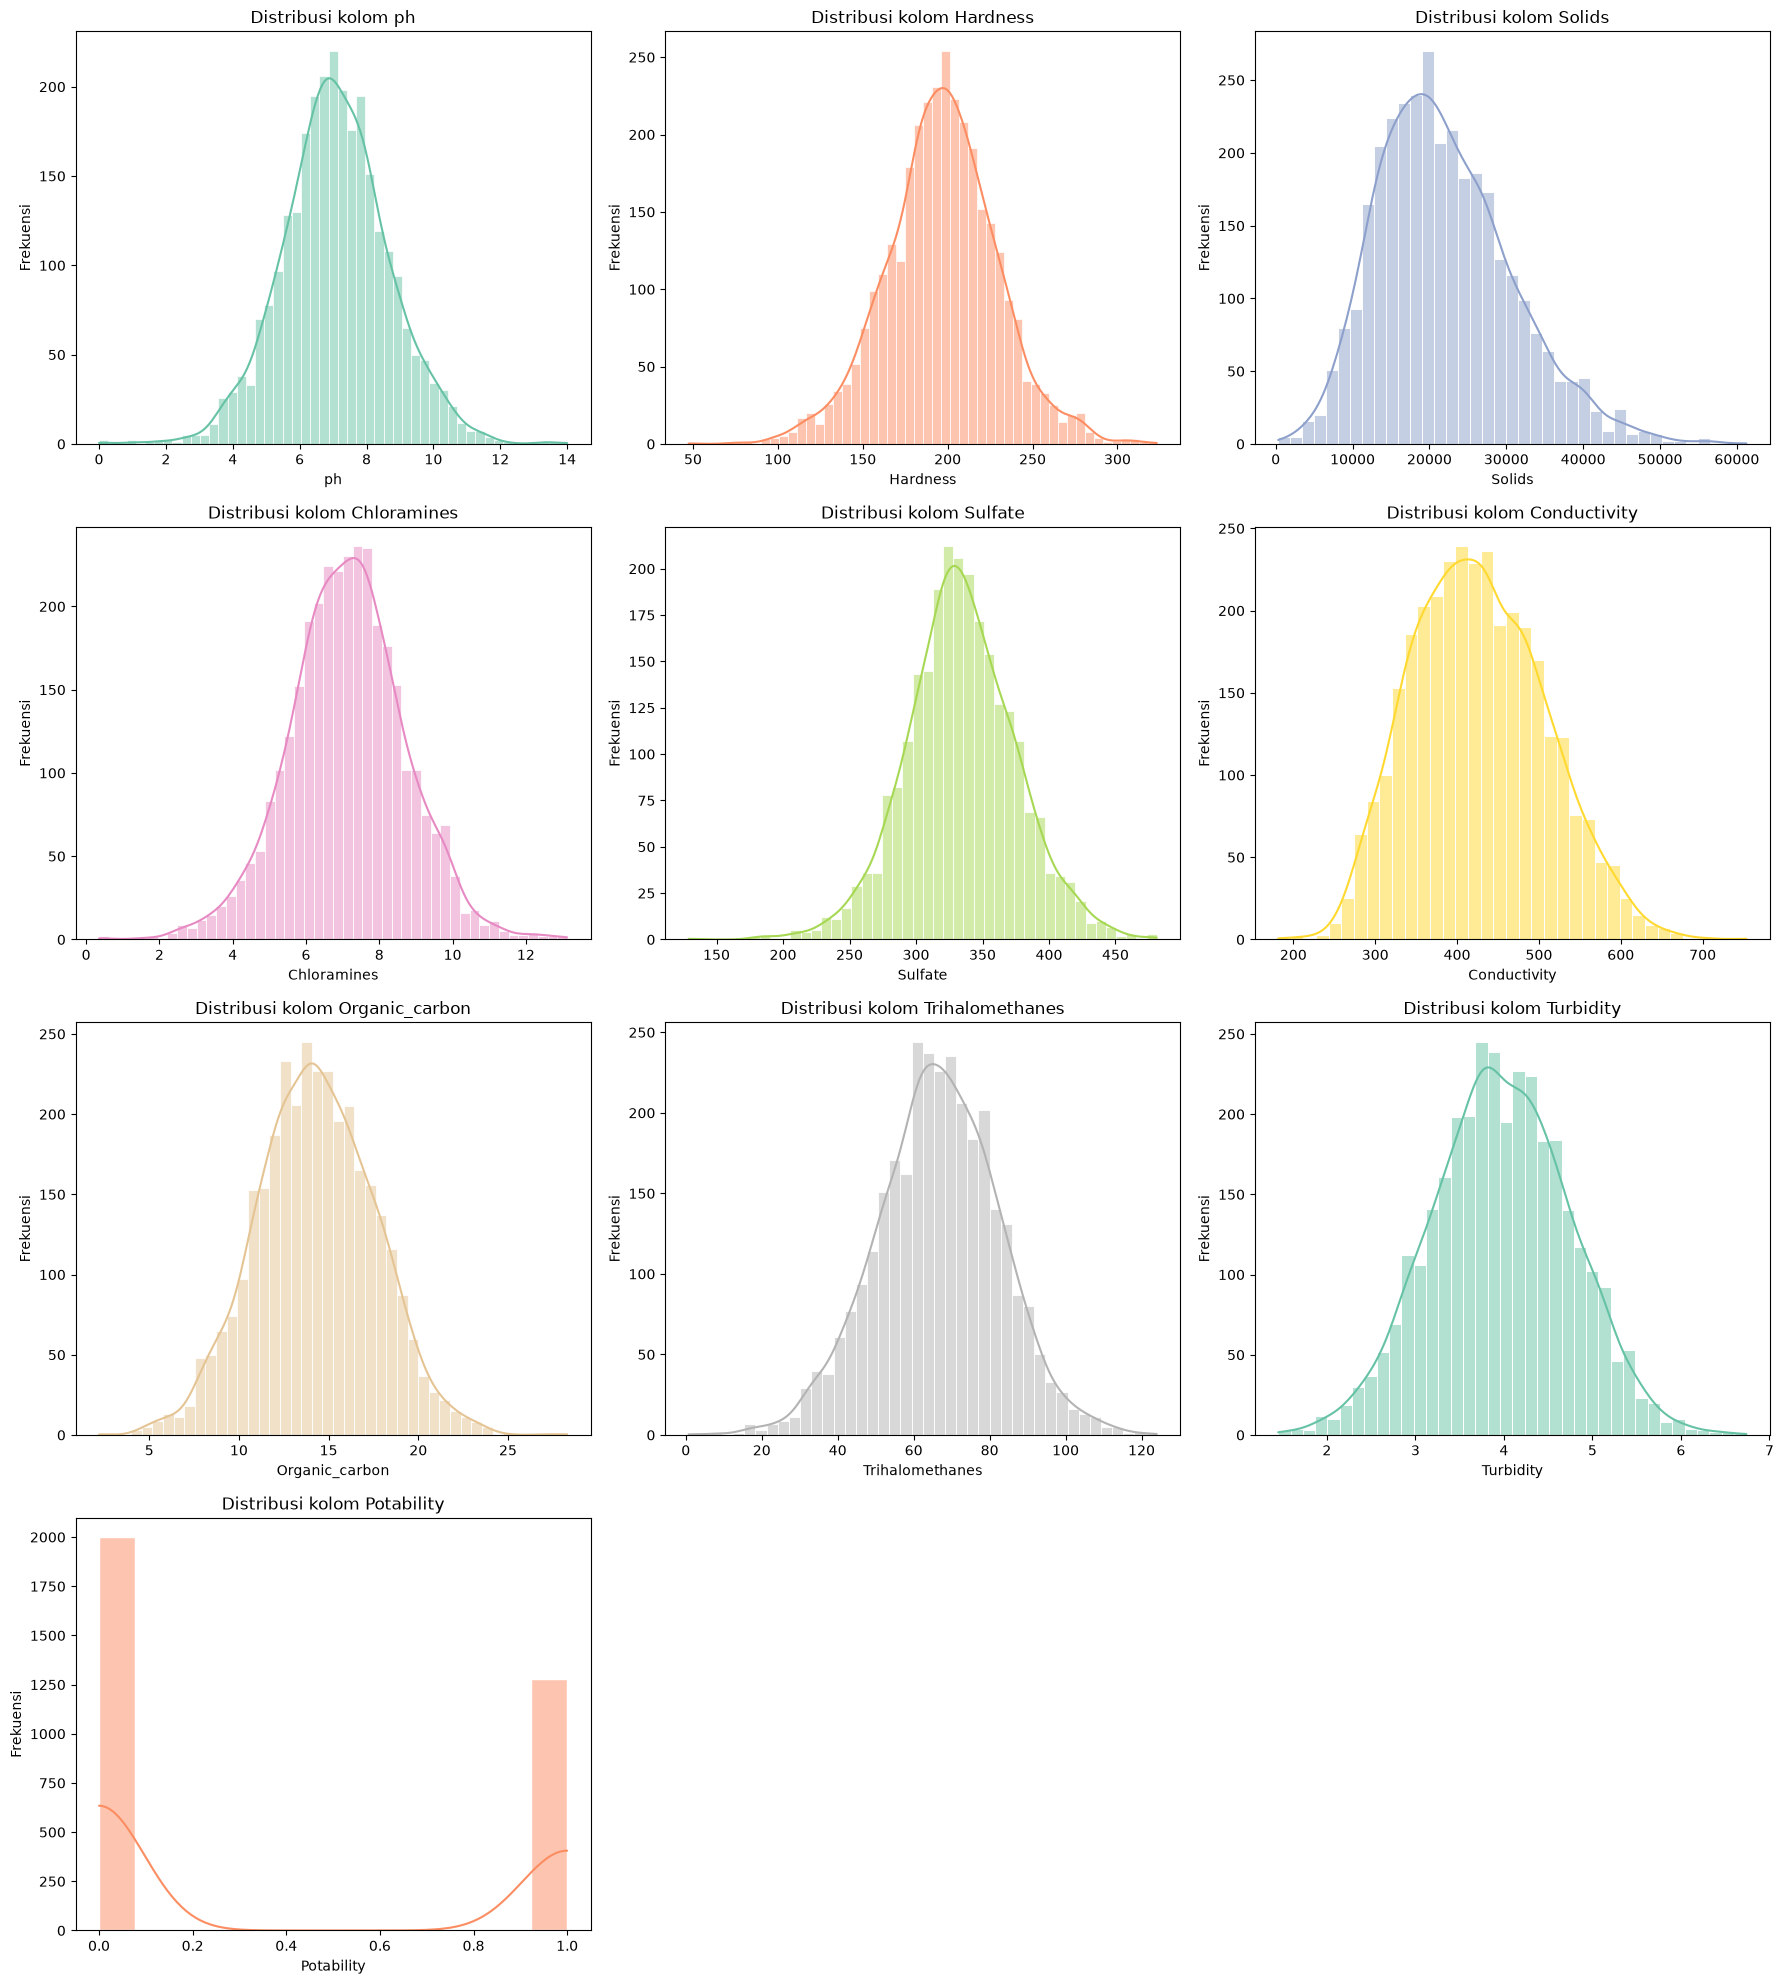

In [ ]:
n_cols = 3
n_rows = int(len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()
sns.set_theme(style='whitegrid')
colors = sns.color_palette(palette='Set2', n_colors=len(numeric_cols))

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, kde=True, color=colors[i], ax=axes[i])
    axes[i].set_title(f'Distribusi kolom {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 3.5 Distribusi kolom target

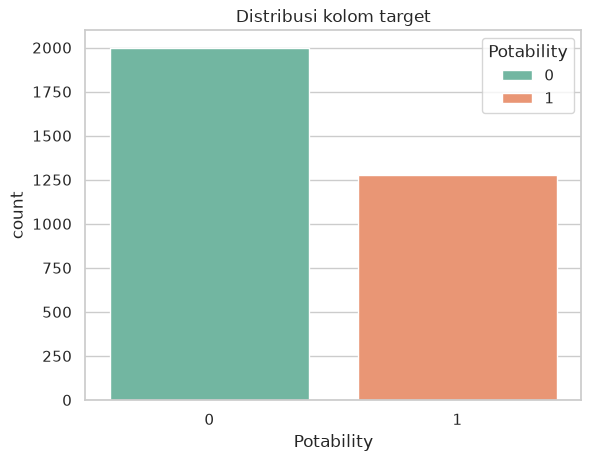

In [12]:
sns.countplot(data=df, x='Potability', palette='Set2', hue='Potability')
plt.title('Distribusi kolom target')
plt.show()

### 3.6 Visualisasi korelasi dengan heatmap

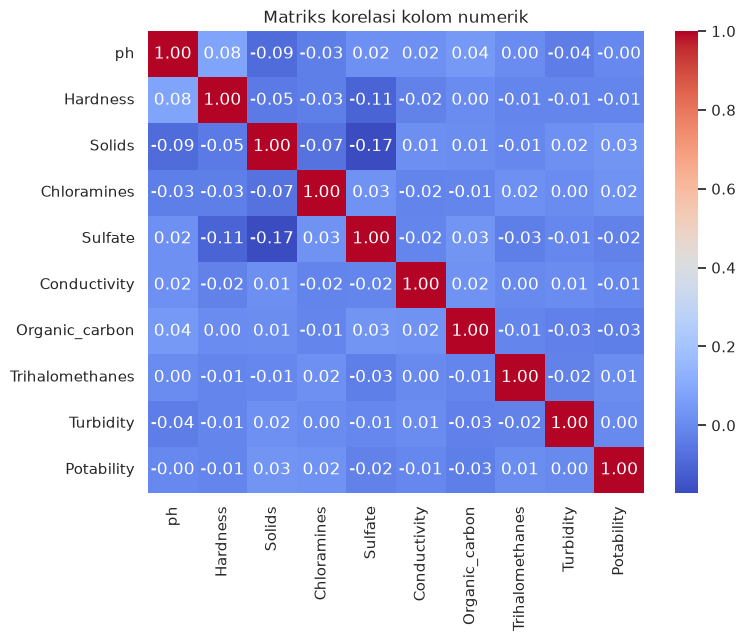

In [13]:
korelasi = df.corr(method='pearson')
plt.figure(figsize=(8,6))
sns.heatmap(korelasi, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Matriks korelasi kolom numerik')
plt.show()

---
## 4. Data Preprocessing

### 4.1 Memeriksa kembali missing value dan data duplikat

In [14]:
print(f'\nJumlah missing value: {df.isnull().sum().sum()}')
print(f'---missing value per kolom--- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'Jumlah data duplikat: {df.duplicated().sum()}')


Jumlah missing value: 1434
---missing value per kolom--- 
ph                 491
Sulfate            781
Trihalomethanes    162
dtype: int64
Jumlah data duplikat: 0


### 4.2 Penanganan missing value dengan mengganti dengan mean

In [15]:
missing = ['ph', 'Sulfate', 'Trihalomethanes']

for col in missing:
    df[col] = df[col].fillna(df[col].mean())

print(f'Sisa missing value: {df.isnull().sum().sum()}')

Sisa missing value: 0


### 4.3 Memisah kolom fitur ($X$) dan kolom target ($y$)

In [16]:
X = df.drop(columns=['Potability'])
y = df['Potability']

print(f'Dimensi kolom fitur (X): {X.shape[0]} Baris, {X.shape[1]} Kolom')
print(f'Dimensi kolom target(y): {y.shape[0]} Baris')

Dimensi kolom fitur (X): 3276 Baris, 9 Kolom
Dimensi kolom target(y): 3276 Baris


### 4.4 Split data latih dan data uji

In [17]:
np.random.seed(42)
idx_train_list, idx_test_list = [], []

for kelas in np.unique(y):
    idx_kelas = np.where(y == kelas)[0]
    idx_acak = np.random.permutation(idx_kelas)
    batas = int(0.8 * len(idx_acak))
    idx_train_list.append(idx_acak[:batas])
    idx_test_list.append(idx_acak[batas:])

idx_train = np.random.permutation(np.concatenate(idx_train_list))
idx_test = np.random.permutation(np.concatenate(idx_test_list))

X_train = X.iloc[idx_train].copy().reset_index(drop=True)
X_test = X.iloc[idx_test].copy().reset_index(drop=True)
y_train = y.iloc[idx_train].reset_index(drop=True)
y_test = y.iloc[idx_test].reset_index(drop=True)

print(f'Dimensi data train: {X_train.shape[0]} Baris, {X_train.shape[1]} Kolom')
print(f'Dimensi data test: {X_test.shape[0]} Baris')

Dimensi data train: 2620 Baris, 9 Kolom
Dimensi data test: 656 Baris


### 4.5 Penanganan outlier dengan capping

In [18]:
numeric = X_train.columns.tolist()

X_train_cap = X_train.copy()
X_test_cap = X_test.copy()

for col in numeric:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    X_train_cap[col] = np.clip(X_train[col], lower, upper)
    X_test_cap[col] = np.clip(X_test[col], lower, upper)

### 4.6 Visualisasi boxplot setelah proses capping

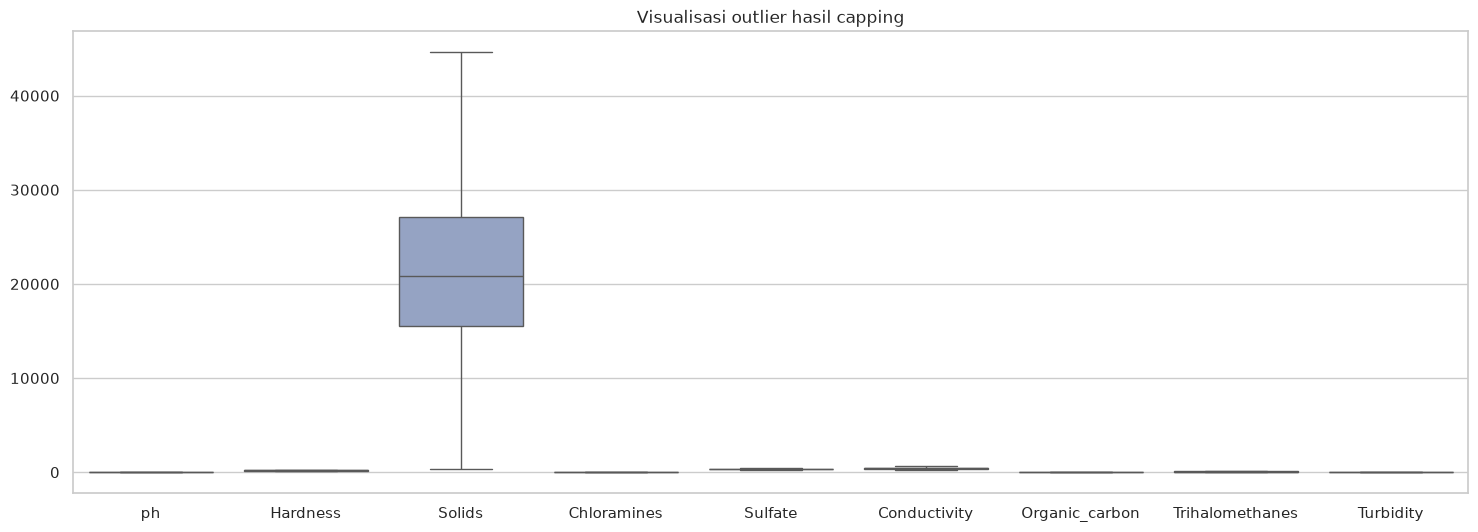

In [19]:
plt.figure(figsize=(18, 6))
sns.boxplot(data=X_train_cap, palette='Set2')
plt.title('Visualisasi outlier hasil capping')
plt.show()

### 4.8 Feature scalling

In [20]:
cols = X_train_cap.columns.tolist()

X_train_scaling = X_train_cap.copy()
X_test_scaling = X_test_cap.copy()

for col in X_train_scaling:
    mean = X_train_cap[col].mean()
    std = X_train_cap[col].std()
    X_train_scaling[col] = (X_train_scaling[col] - mean) / std
    X_test_scaling[col] = (X_test_scaling[col] - mean) / std

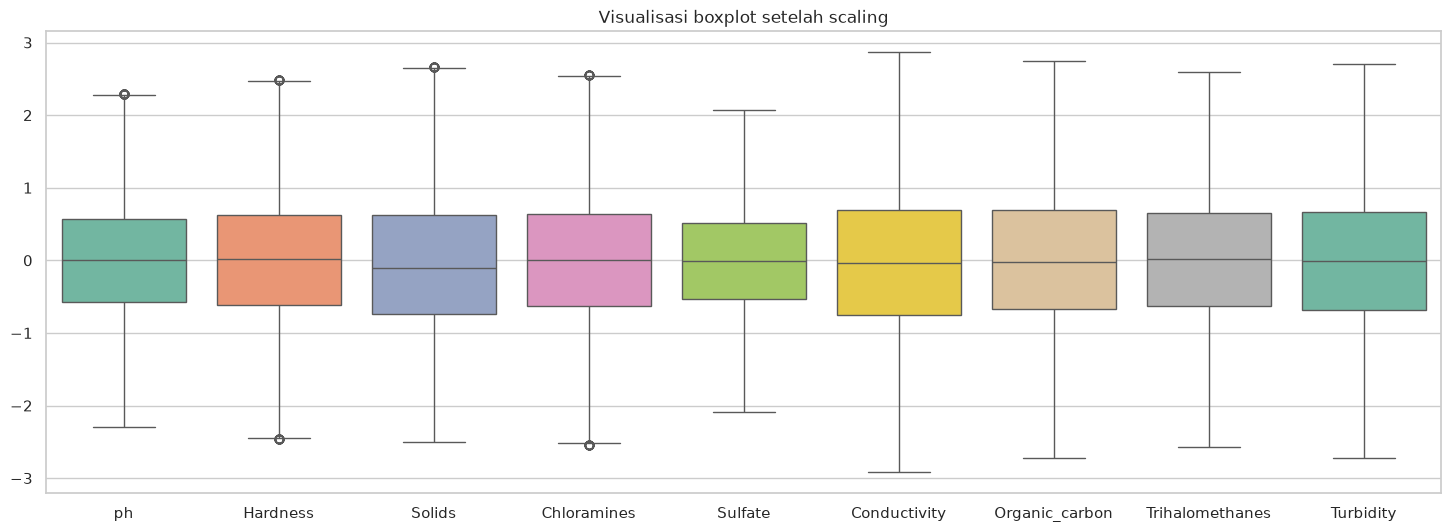

In [21]:
plt.figure(figsize=(18, 6))
sns.boxplot(data=X_train_scaling, palette='Set2')
plt.title('Visualisasi boxplot setelah scaling')
plt.show()